<a href="https://colab.research.google.com/github/Khushal-Sonar/Machine_Learning_Lab/blob/main/Practical_8_Short.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# DNN for Digit Classification using Keras

import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [4]:
# 1. Load MNIST Dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training:", x_train.shape)
print("Testing:", x_test.shape)

Training: (60000, 28, 28)
Testing: (10000, 28, 28)


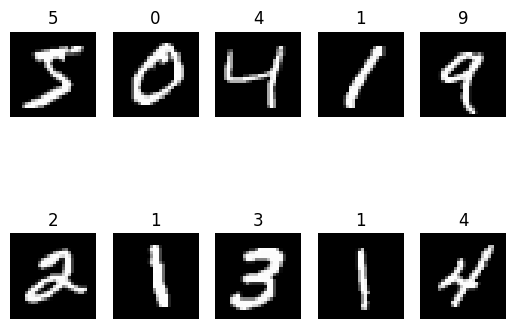

In [5]:
# 2. Display Sample Images
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(y_train[i])
    plt.axis("off")
plt.show()

In [6]:
# 3. Normalize Data
x_train = x_train / 255.0
x_test = x_test / 255.0

In [7]:
# 4. Build 3-Layer DNN
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation="relu"),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [8]:
# 5. Display Model Architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# 6. Compile Model
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

In [10]:
# 7. Train Model
history = model.fit(x_train, y_train,
                    epochs=5, batch_size=32,
                    validation_split=0.1)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9245 - loss: 0.2592 - val_accuracy: 0.9663 - val_loss: 0.1122
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9663 - loss: 0.1092 - val_accuracy: 0.9693 - val_loss: 0.0977
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9765 - loss: 0.0757 - val_accuracy: 0.9713 - val_loss: 0.0920
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.9822 - loss: 0.0572 - val_accuracy: 0.9795 - val_loss: 0.0752
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9858 - loss: 0.0441 - val_accuracy: 0.9797 - val_loss: 0.0778


In [11]:
# 8. Evaluate Model
loss, acc = model.evaluate(x_test, y_test)
print("Test Loss:", loss)
print("Test Accuracy:", acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9774 - loss: 0.0772
Test Loss: 0.0771653950214386
Test Accuracy: 0.977400004863739


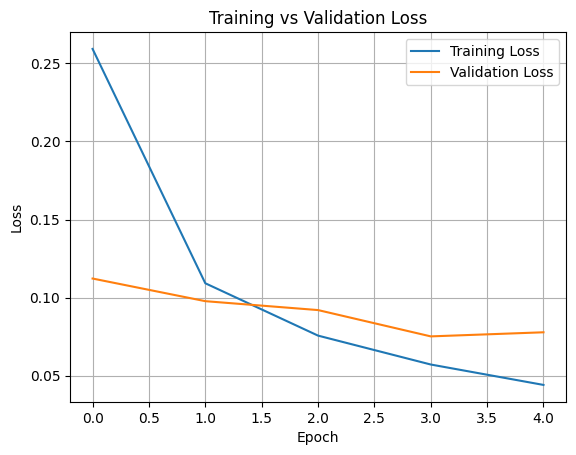

In [12]:
# 9. Plot Training and Validation Loss
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

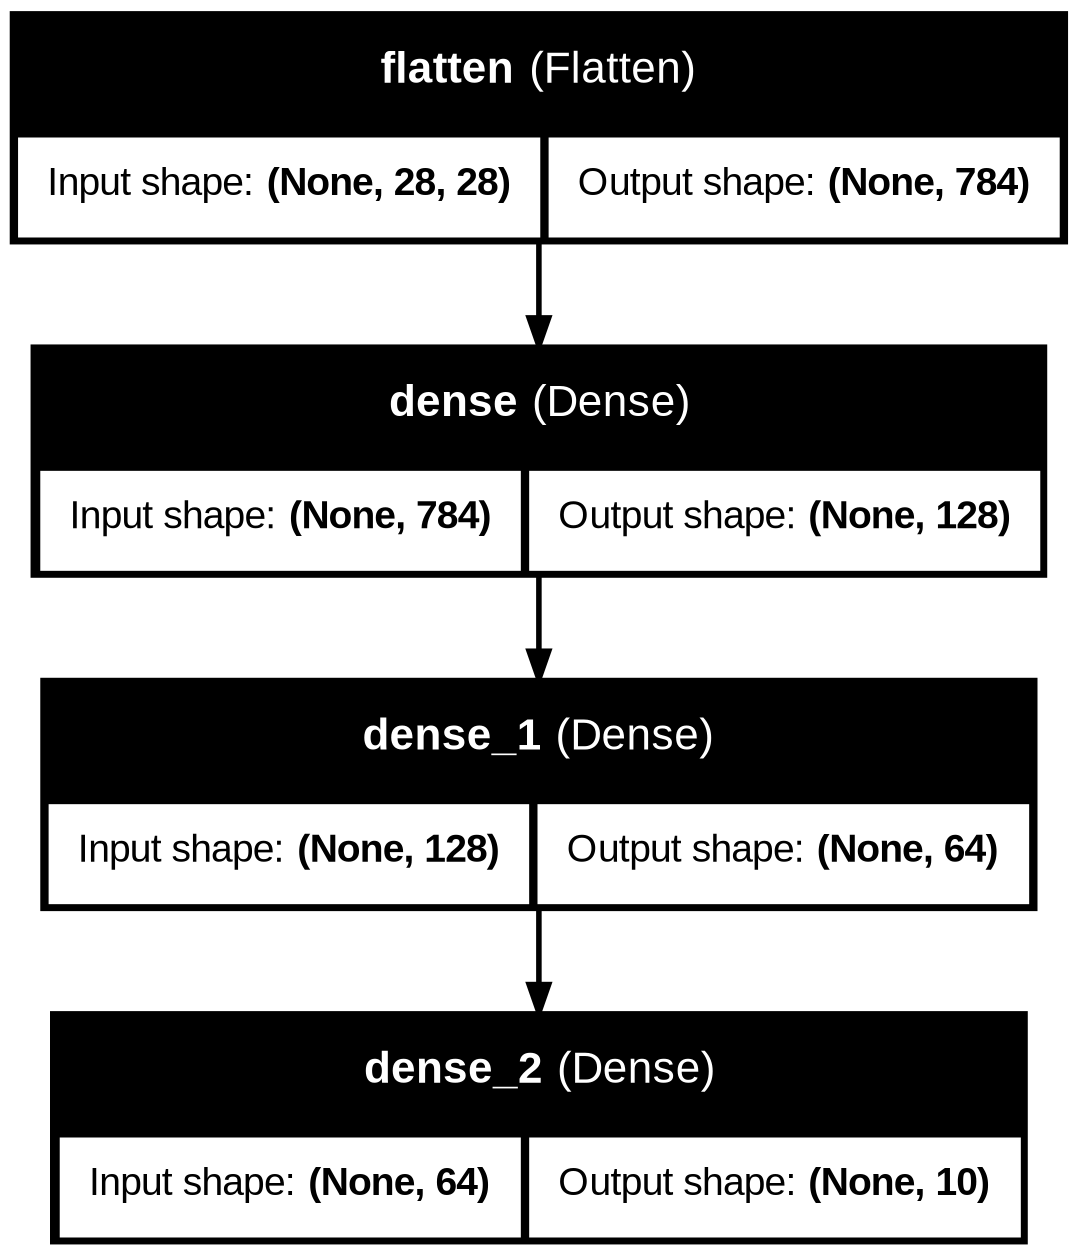

In [13]:
# 10. Visualize Network Architecture
tf.keras.utils.plot_model(model, show_shapes=True,
                           show_layer_names=True,
                           to_file="dnn_architecture.png")

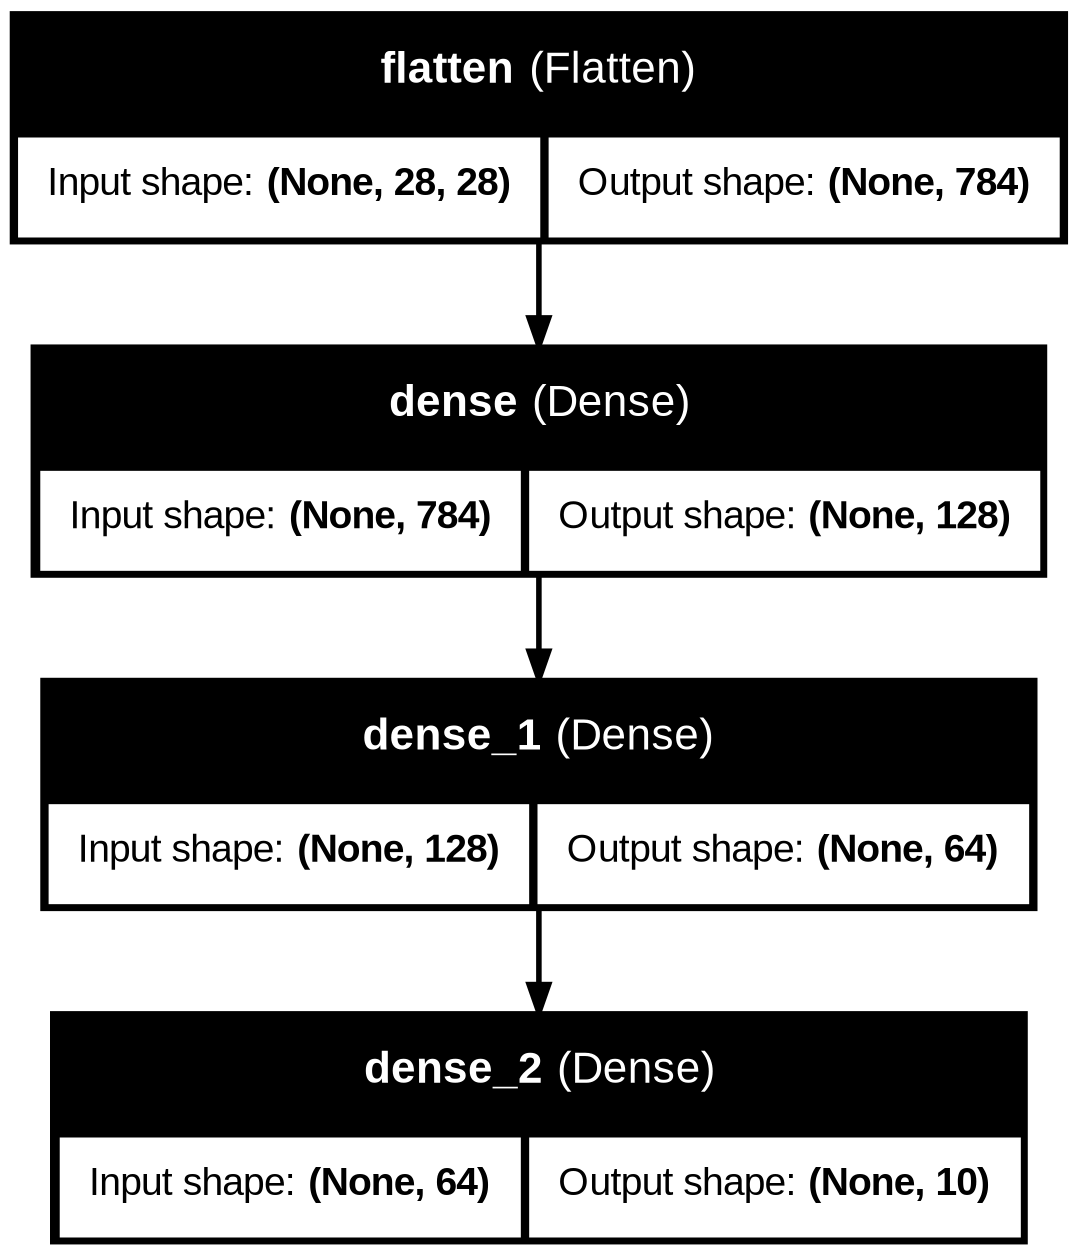

In [14]:
# 10. Visualize Network Architecture
tf.keras.utils.plot_model(model, show_shapes=True,
                           show_layer_names=True,
                           to_file="dnn_architecture.png")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step


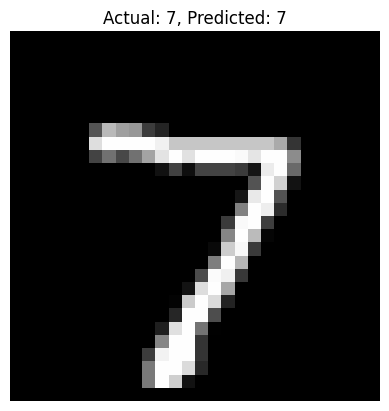

In [15]:
# 11. Predict Sample Digit
p = model.predict(x_test[:1])
digit = np.argmax(p[0])

plt.imshow(x_test[0], cmap="gray")
plt.title(f"Actual: {y_test[0]}, Predicted: {digit}")
plt.axis("off")
plt.show()